# FINANCIAL RISK AND LOAN ANALYSIS

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Financial Risk And Loan default Analysis")


Financial Risk And Loan default Analysis


In [3]:
df=pd.read_csv(r"C:\Users\nidap\Desktop\main project\PYTHON\financial risk analysis using EDA\loan_train.csv")
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,last_credit_pull_d,pub_rec_bankruptcies
0,540179,697401,10000,10000,9975.0,36 months,13.23%,338.05,C,C1,...,11943.68,10000.00,1973.61,0.0,0.00,0.0,Sep-12,3536.63,Mar-14,0.0
1,585434,752191,14000,14000,13775.0,36 months,7.88%,437.94,A,A5,...,15470.79,14000.00,1723.48,0.0,0.00,0.0,May-13,2603.31,Jan-16,0.0
2,457736,569298,9475,9475,9475.0,36 months,8.94%,301.04,A,A5,...,10472.09,9475.00,997.09,0.0,0.00,0.0,May-11,5365.49,Aug-15,0.0
3,734349,930860,4000,4000,4000.0,36 months,7.29%,124.04,A,A4,...,4425.26,4000.00,425.26,0.0,0.00,0.0,Jul-13,1336.22,May-15,0.0
4,1050080,1281522,3600,3600,3600.0,36 months,6.62%,110.54,A,A2,...,2321.34,2004.17,306.88,0.0,10.29,0.0,Sep-13,110.54,May-16,0.0


In [4]:
print("Dataset shape:",df.shape)

Dataset shape: (27003, 47)


In [5]:
print("Dataset information:",df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27003 entries, 0 to 27002
Data columns (total 47 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       27003 non-null  int64  
 1   member_id                27003 non-null  int64  
 2   loan_amnt                27003 non-null  int64  
 3   funded_amnt              27003 non-null  int64  
 4   funded_amnt_inv          27003 non-null  float64
 5   term                     27003 non-null  object 
 6   int_rate                 27003 non-null  object 
 7   installment              27003 non-null  float64
 8   grade                    27003 non-null  object 
 9   sub_grade                27003 non-null  object 
 10  emp_title                25321 non-null  object 
 11  emp_length               26273 non-null  object 
 12  home_ownership           27003 non-null  object 
 13  annual_inc               27003 non-null  float64
 14  verification_status   

In [6]:
print("dataset columns:",df.columns)

dataset columns: Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'url', 'desc', 'purpose', 'title', 'zip_code',
       'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
       'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record',
       'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv',
       'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'last_credit_pull_d', 'pub_rec_bankruptcies'],
      dtype='object')


In [6]:
print("Dataset statistics:",df.describe())

Dataset statistics:                  id     member_id     loan_amnt   funded_amnt  \
count  2.700300e+04  2.700300e+04  27003.000000  27003.000000   
mean   6.763007e+05  8.422473e+05  11087.946710  10816.216717   
std    2.090440e+05  2.642541e+05   7392.758683   7131.666342   
min    5.473400e+04  7.069900e+04    500.000000    500.000000   
25%    5.126630e+05  6.617755e+05   5300.000000   5175.000000   
50%    6.570520e+05  8.400720e+05   9750.000000   9600.000000   
75%    8.271015e+05  1.035238e+06  15000.000000  15000.000000   
max    1.077430e+06  1.314167e+06  35000.000000  35000.000000   

       funded_amnt_inv   installment    annual_inc   loan_status  \
count     27003.000000  27003.000000  2.700300e+04  27003.000000   
mean      10251.064645    323.375002  6.877771e+04      0.147280   
std        7066.203699    209.866524  6.764853e+04      0.354391   
min           0.000000     15.690000  4.000000e+03      0.000000   
25%        5000.000000    165.805000  4.000000e+04    

In [4]:
print("null values:",df.isnull().sum())

null values: id                             0
member_id                      0
loan_amnt                      0
funded_amnt                    0
funded_amnt_inv                0
term                           0
int_rate                       0
installment                    0
grade                          0
sub_grade                      0
emp_title                   1682
emp_length                   730
home_ownership                 0
annual_inc                     0
verification_status            0
issue_d                        0
loan_status                    0
url                            0
desc                        8779
purpose                        0
title                          9
zip_code                       0
addr_state                     0
dti                            0
delinq_2yrs                    0
earliest_cr_line               0
inq_last_6mths                 0
mths_since_last_delinq     17395
mths_since_last_record     25065
open_acc                      

In [5]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))

id                          0.00
member_id                   0.00
loan_amnt                   0.00
funded_amnt                 0.00
funded_amnt_inv             0.00
term                        0.00
int_rate                    0.00
installment                 0.00
grade                       0.00
sub_grade                   0.00
emp_title                   6.23
emp_length                  2.70
home_ownership              0.00
annual_inc                  0.00
verification_status         0.00
issue_d                     0.00
loan_status                 0.00
url                         0.00
desc                       32.51
purpose                     0.00
title                       0.03
zip_code                    0.00
addr_state                  0.00
dti                         0.00
delinq_2yrs                 0.00
earliest_cr_line            0.00
inq_last_6mths              0.00
mths_since_last_delinq     64.42
mths_since_last_record     92.82
open_acc                    0.00
pub_rec   

In [6]:
df.drop(['mths_since_last_delinq',
         'mths_since_last_record'], axis=1, inplace=True)


In [7]:
df['emp_title'] = df['emp_title'].fillna('Unknown')
df['emp_length'] = df['emp_length'].fillna(df['emp_length'].mode()[0])
df['desc'] = df['desc'].fillna('Not Available')
df['title'] = df['title'].fillna(df['title'].mode()[0])
df.isnull().sum()

id                           0
member_id                    0
loan_amnt                    0
funded_amnt                  0
funded_amnt_inv              0
term                         0
int_rate                     0
installment                  0
grade                        0
sub_grade                    0
emp_title                    0
emp_length                   0
home_ownership               0
annual_inc                   0
verification_status          0
issue_d                      0
loan_status                  0
url                          0
desc                         0
purpose                      0
title                        0
zip_code                     0
addr_state                   0
dti                          0
delinq_2yrs                  0
earliest_cr_line             0
inq_last_6mths               0
open_acc                     0
pub_rec                      0
revol_bal                    0
revol_util                  35
total_acc                    0
out_prnc

In [85]:
Q1 = df["loan_amnt"].quantile(0.25)
Q3 = df["loan_amnt"].quantile(0.75)
IQR = Q3 - Q1
outliers = df[
    (df["loan_amnt"] < Q1 - 1.5 * IQR) |
    (df["loan_amnt"] > Q3 + 1.5 * IQR)]
print("Loan Amount count Outliers:", len(outliers))

Loan Amount count Outliers: 790


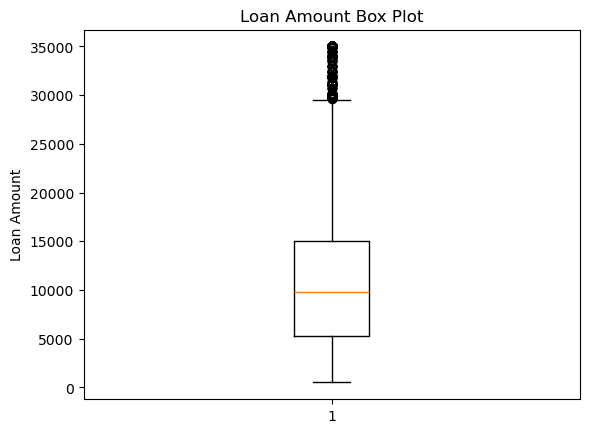

In [86]:
plt.boxplot(df["loan_amnt"])
plt.title("Loan Amount Box Plot")
plt.ylabel("Loan Amount")
plt.show()

In [15]:
df['revol_util'] = pd.to_numeric(df['revol_util'], errors='coerce')
df['revol_util'] = df['revol_util'].fillna(
    df['revol_util'].median())
df['pub_rec_bankruptcies'] = df['pub_rec_bankruptcies'].fillna(
    df['pub_rec_bankruptcies'].median())
print("Total null values:", df.isnull().sum().sum())

Total null values: 0


In [21]:
df['emp_title'] = df['emp_title'].fillna('Unknown')
df['emp_length'] = df['emp_length'].fillna(
    df['emp_length'].mode()[0])
df['desc'] = df['desc'].fillna('Not Available')
df['title'] = df['title'].fillna(
    df['title'].mode()[0])
df['last_pymnt_d'] = df['last_pymnt_d'].fillna(
    df['last_pymnt_d'].mode()[0])
df['last_credit_pull_d'] = df['last_credit_pull_d'].fillna(
    df['last_credit_pull_d'].mode()[0])
print("Total null values:", df.isnull().sum().sum())

Total null values: 0


In [18]:
print("Total null values:", df.isnull().sum().sum())

Total null values: 0


In [123]:
df.duplicated().sum()

np.int64(0)

In [25]:
df["loan_status"].value_counts()

loan_status
0    23026
1     3977
Name: count, dtype: int64

In [26]:
print(df['loan_status'].value_counts() / len(df) * 100)

loan_status
0    85.272007
1    14.727993
Name: count, dtype: float64


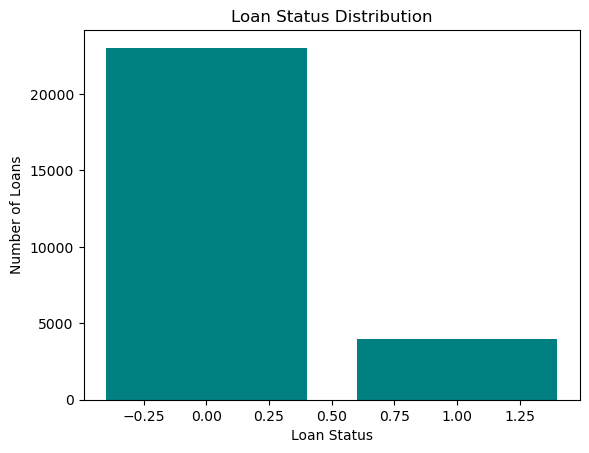

In [27]:
loan_status = df['loan_status'].value_counts()
plt.bar(loan_status.index, loan_status.values, color='teal')
plt.title('Loan Status Distribution')
plt.xlabel('Loan Status')
plt.ylabel('Number of Loans')
plt.show()

In [29]:
df['int_rate'] = df['int_rate'].str.replace('%', '', regex=False)
df['int_rate'] = pd.to_numeric(df['int_rate'], errors='coerce')
interest_rate=df.groupby('loan_status')['int_rate'].mean()
print(interest_rate)

loan_status
0    11.594165
1    13.816661
Name: int_rate, dtype: float64


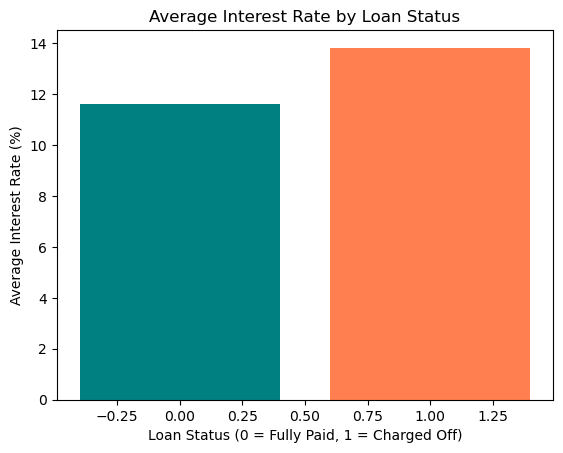

In [30]:
plt.bar(interest_rate.index, interest_rate.values,color=['teal', 'coral'])
plt.title('Average Interest Rate by Loan Status')
plt.xlabel('Loan Status (0 = Fully Paid, 1 = Charged Off)')
plt.ylabel('Average Interest Rate (%)')
plt.show()

In [31]:
grade_default=df.groupby('grade')['loan_status'].mean() * 100
print(grade_default)

grade
A     6.110009
B    12.150446
C    17.531634
D    22.338618
E    27.502691
F    31.518625
G    34.246575
Name: loan_status, dtype: float64


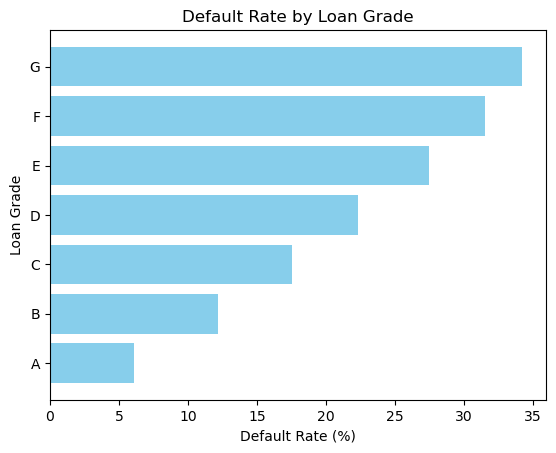

In [32]:
plt.barh(grade_default.index, grade_default.values, color='skyblue')
plt.title('Default Rate by Loan Grade')
plt.xlabel('Default Rate (%)')
plt.ylabel('Loan Grade')
plt.show()

In [34]:
df['loan_amount_group'] = pd.cut(
    df['loan_amnt'],
    bins=4,
    labels=['Low', 'Medium', 'High', 'Very High']
)
loan_amount=df.groupby('loan_amount_group',observed=False)['loan_status'].mean() * 100
print(loan_amount)

loan_amount_group
Low          13.414728
Medium       14.104683
High         18.757954
Very High    21.823770
Name: loan_status, dtype: float64


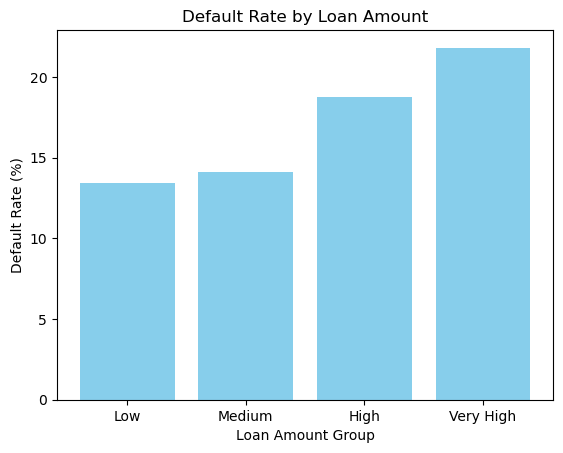

In [35]:
plt.bar(loan_amount.index, loan_amount.values, color='skyblue')
plt.title('Default Rate by Loan Amount')
plt.xlabel('Loan Amount Group')
plt.ylabel('Default Rate (%)')
plt.show()

In [36]:
df['income_group'] = pd.qcut(df['annual_inc'],q=4,labels=['Low', 'Medium', 'High', 'Very High'])
income_default=df.groupby('income_group', observed=True)['loan_status'].mean() * 100
print(income_default)

income_group
Low          18.236326
Medium       15.213193
High         14.164052
Very High    11.244622
Name: loan_status, dtype: float64


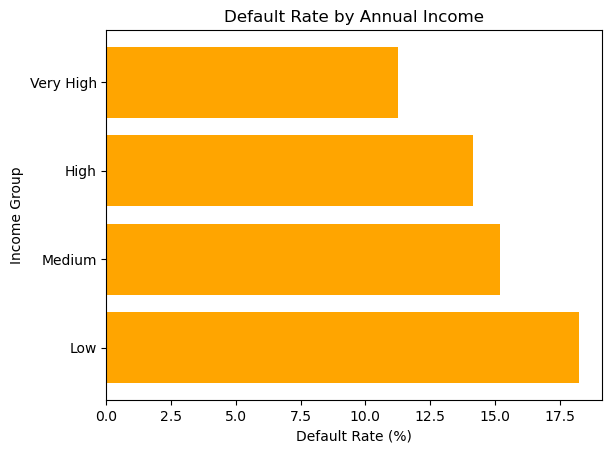

In [37]:
plt.barh(income_default.index, income_default.values, color='orange')
plt.title('Default Rate by Annual Income')
plt.xlabel('Default Rate (%)')
plt.ylabel('Income Group')
plt.show()

In [38]:
purpose_default = df.groupby('purpose')['loan_status'].mean() * 100
print(purpose_default)

purpose
car                   10.133843
credit_card           11.057692
debt_consolidation    15.386448
educational           15.348837
home_improvement      13.138686
house                 16.541353
major_purchase        10.742706
medical               16.733871
moving                14.936709
other                 16.531065
renewable_energy      17.808219
small_business        27.027027
vacation              13.671875
wedding               10.419907
Name: loan_status, dtype: float64


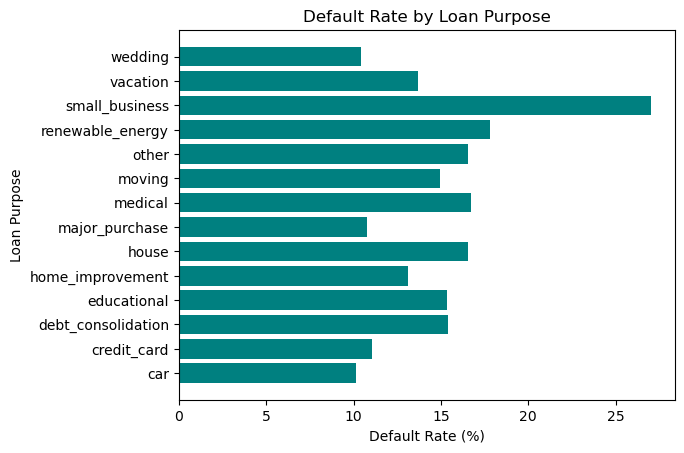

In [39]:
plt.barh(purpose_default.index, purpose_default.values, color='teal')
plt.title('Default Rate by Loan Purpose')
plt.xlabel('Default Rate (%)')
plt.ylabel('Loan Purpose')
plt.show()

In [40]:
term_default = df.groupby('term')['loan_status'].mean() * 100
print(term_default)

term
36 months    11.235404
60 months    25.479535
Name: loan_status, dtype: float64


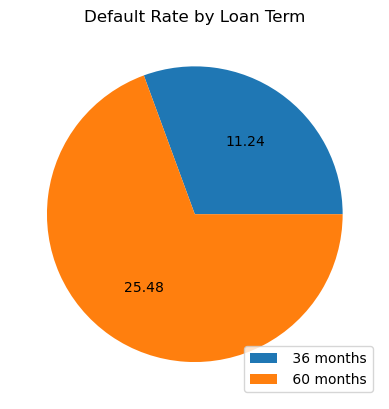

In [44]:
plt.pie(term_default.values,labels=None,autopct=lambda p:f'{p * sum(term_default.values) / 100:.2f}')
plt.title('Default Rate by Loan Term')
plt.ylabel('')
plt.legend(term_default.index)
plt.show()

In [45]:
df['revol_util_group'] = pd.cut(df['revol_util'],bins=4,labels=['Low', 'Medium', 'High', 'Very High'])
credit_usage = df.groupby('revol_util_group', observed=True)['loan_status'].mean() * 100
print(credit_usage)

revol_util_group
Low          10.128858
Medium       13.222675
High         16.557674
Very High    19.409912
Name: loan_status, dtype: float64


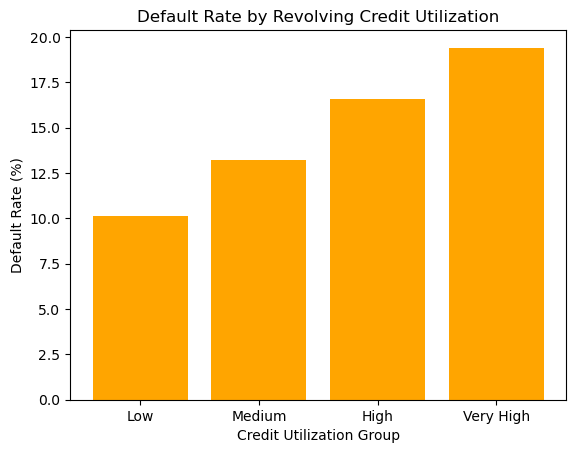

In [46]:
plt.bar(credit_usage.index, credit_usage.values, color='orange')
plt.title('Default Rate by Revolving Credit Utilization')
plt.xlabel('Credit Utilization Group')
plt.ylabel('Default Rate (%)')
plt.show()

In [47]:
debt_default = df.groupby(pd.cut(df['dti'], bins=4),observed=True)['loan_status'].mean() * 100
print(debt_default)

dti
(-0.03, 7.498]      12.533333
(7.498, 14.995]     14.134204
(14.995, 22.492]    16.322788
(22.492, 29.99]     16.781237
Name: loan_status, dtype: float64


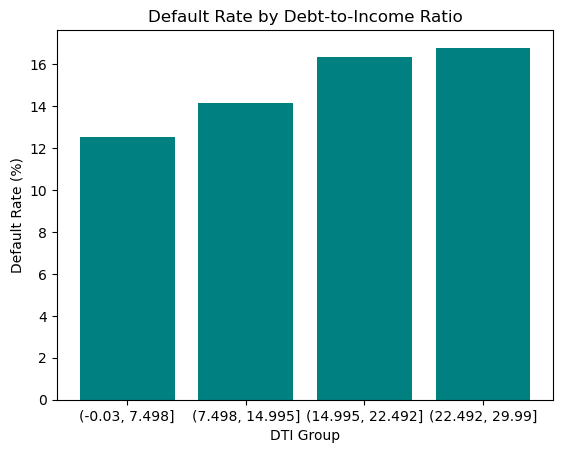

In [49]:
plt.bar(debt_default.index.astype(str), debt_default.values, color='teal')
plt.title('Default Rate by Debt-to-Income Ratio')
plt.xlabel('DTI Group')
plt.ylabel('Default Rate (%)')
plt.show()